# PushT-v0

Push a T-shaped block to a fixed target pose.

**mujoco** · [Environment reference](https://github.com/latent-horizon/pytorch-world/blob/main/docs/guides/environments.md).

A small LeWM baseline experiment: held-out dynamics prediction, a persistence control, and closed-loop planning against random actions. This validates the experiment pipeline; it is not a paper-scale training run.

The named class works directly with the shared experiment and visualization API. Its original collection API remains available. GT is fixed throughout the experiment; training and evaluation use separate reset seeds. RobotCube assets are downloaded once into the existing Menagerie cache.

This notebook benchmarks a fixed symmetric translation: the T moves from (0, 0.06, 0) to (0, −0.10, 0), pushed from above. This is one task instance, not the full random-pose Push-T distribution. Success retains the original position and angle thresholds.

In [1]:
from pathlib import Path

from torch_world.benchmarks import observation_encoder, run_experiment, show_results
from torch_world.envs import PushT
from torch_world.models import LeWM
from torch_world.planning import CEM


## Protocol

2,048 requested training pairs; 400 updates; four evaluation seeds; 60-step evaluation budget. Puzzle training and holdout use disjoint starting states. Other tasks use separate collection seeds. Goal-renderable tasks use goal-image MPC; others learn a reward head on frozen embeddings and plan predicted rewards. Actual simulator returns are scored. The one-step model protocol uses `history=1`.

Rendering defaults to high quality: 128-pixel model inputs and 512-pixel presentation frames. Use `quality="low"` or `quality="medium"` to compare cost and quality; `size` and `render_size` can be set independently.

Training uses random actions through the shared runner, not the older scripted play-data collectors. Both model and random evaluation use the same starts and fixed GT. Seeds vary starting states except for the fixed PushT task; they also control policy randomness.

In [2]:
world = PushT(size=128, quality="high")
SEED, UPDATES = 7, 400
OUTPUT_DIR = Path('../runs/benchmarks/20261017_named_worlds')

# Replace this factory to compare another WorldModel with the same experiment.
def model_factory(observation_shape, action_dim):
    return LeWM(
        observation_encoder(observation_shape), action_dim, embed_dim=32, history=1,
        depth=2, num_heads=4, head_dim=8, mlp_dim=64, proj_dim=64, dropout=0,
    )


def planner_factory(action_dim):
    return CEM(8, action_dim, num_samples=96, num_elites=12, iterations=3, bounds=(-1, 1))

**PushT-v0 · mujoco** — Push a T-shaped block to a fixed target pose. 2 normalized action components in [-1, 1].

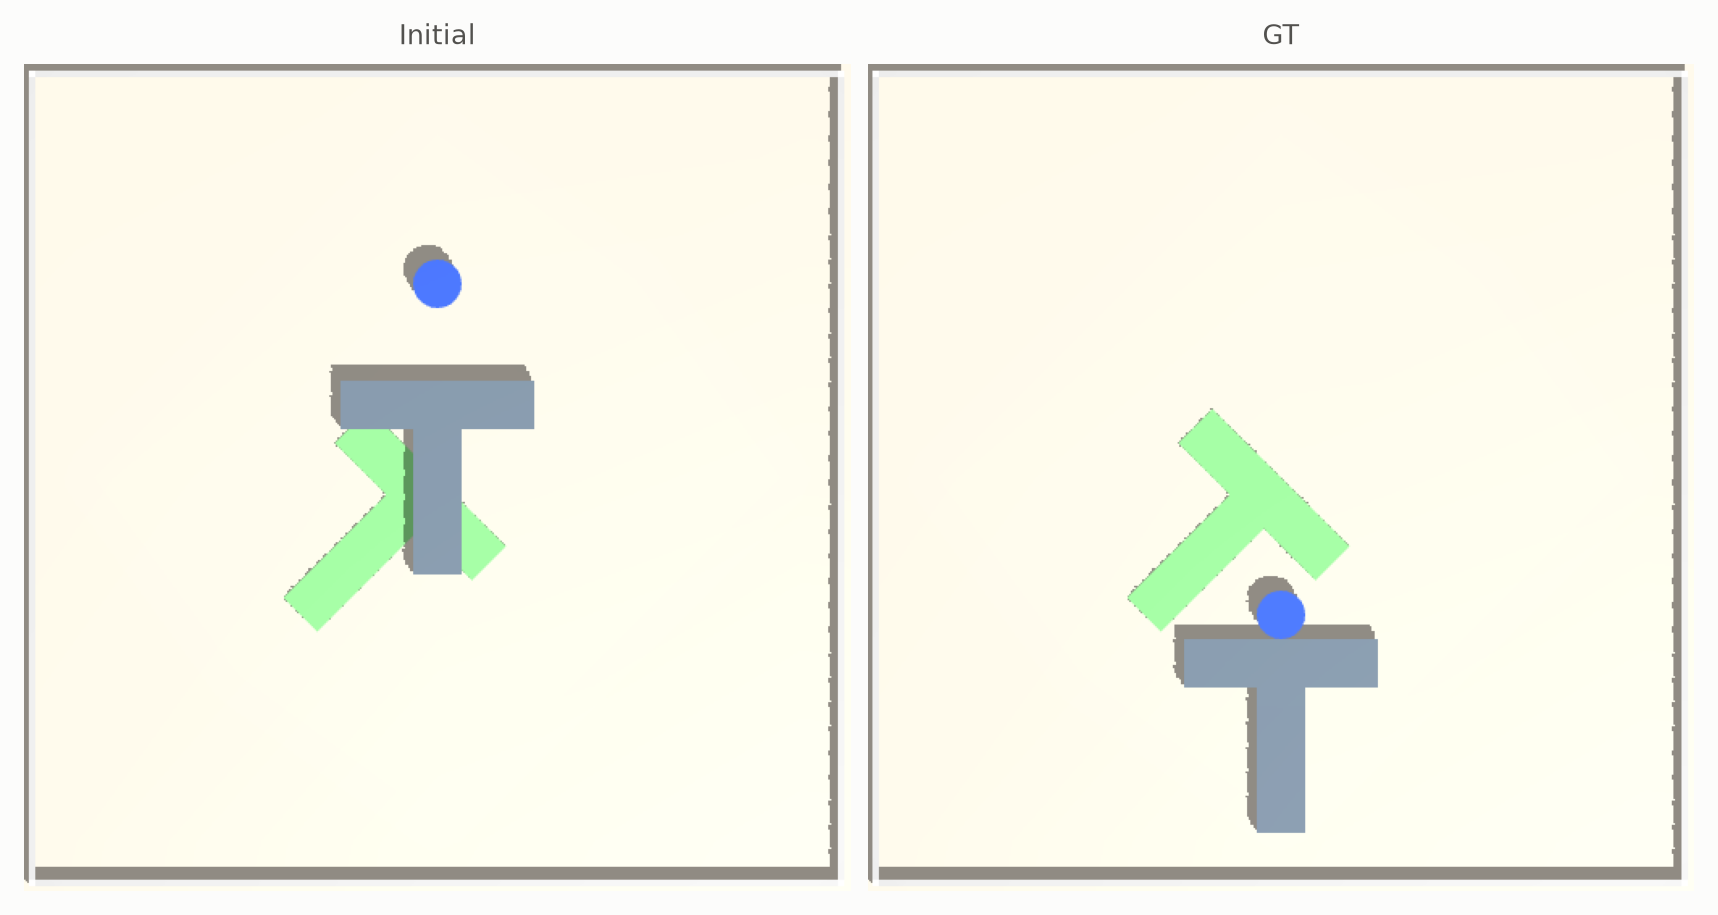

In [3]:
world.show_env()


In [4]:
result = run_experiment(
    world, model_factory=model_factory, planner_factory=planner_factory,
    seed=SEED, updates=UPDATES, output_dir=OUTPUT_DIR,
)


## GT reference

A verified successful episode GIF, separate from the model results. The GT panel remains visible throughout. Reference controllers may use a longer episode budget than model evaluation; the GIF shows actual simulator step numbers.

**PushT-v0** — verified reference episode · 11 simulator steps; separate from model evaluation.

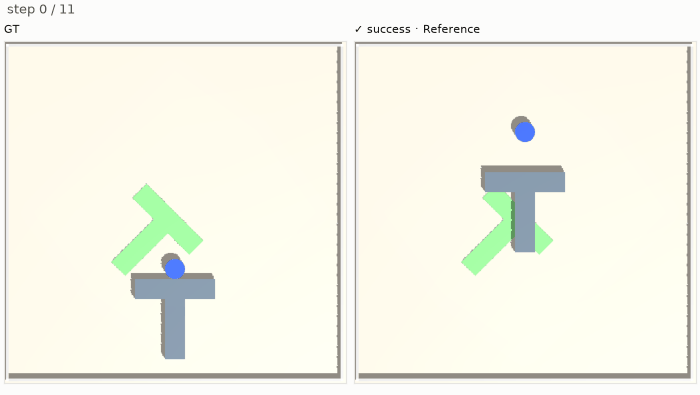

Static preview of the recorded episode. Rerun this cell to view the animation.

In [5]:
world.show_success()


## Results

Lower prediction error alone does not establish planning competence.

**PushT-v0 · LeWM** — pixels observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 74.6 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 1.9189 |
| Persistence | 0.1000 |

Latent standard deviation: **0.672**. Latent errors are comparable within this model; their scale differs between models.

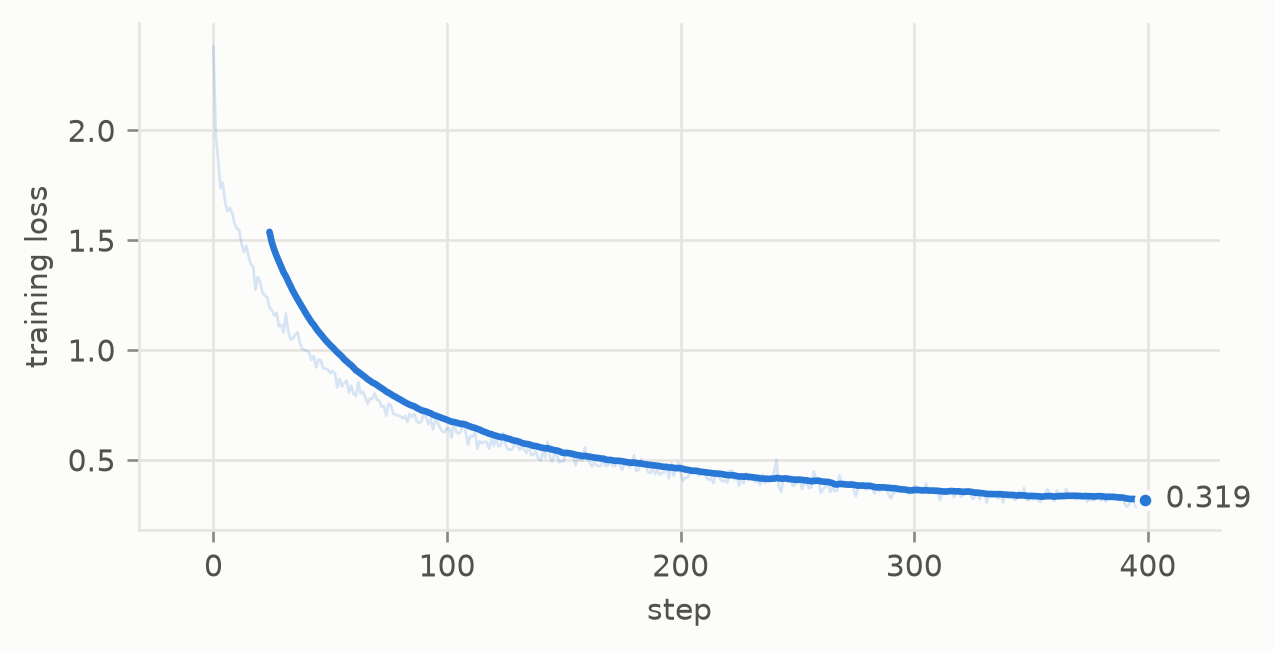

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 49%] | 60.0 | 0.150 |
| random | 0% [0%, 49%] | 60.0 | 0.167 |

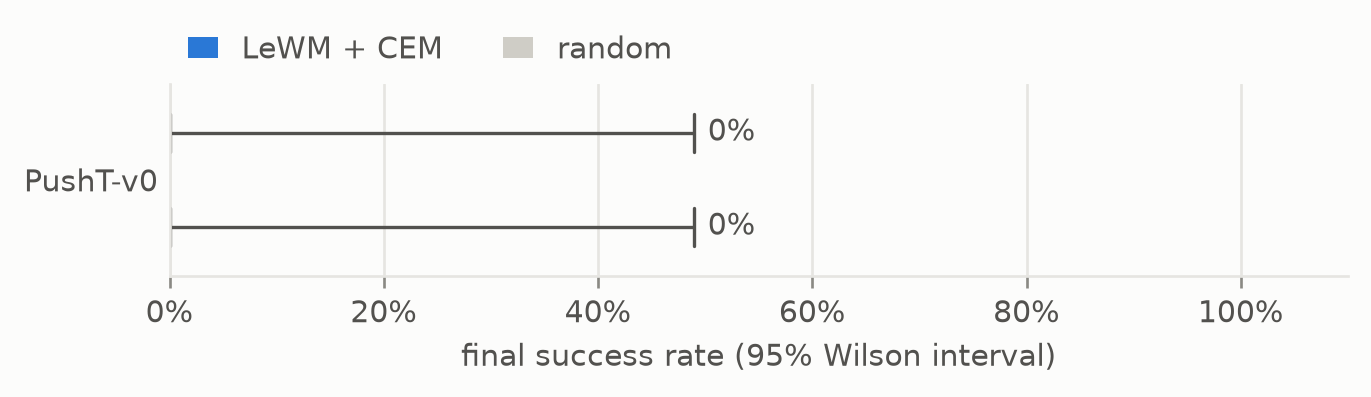

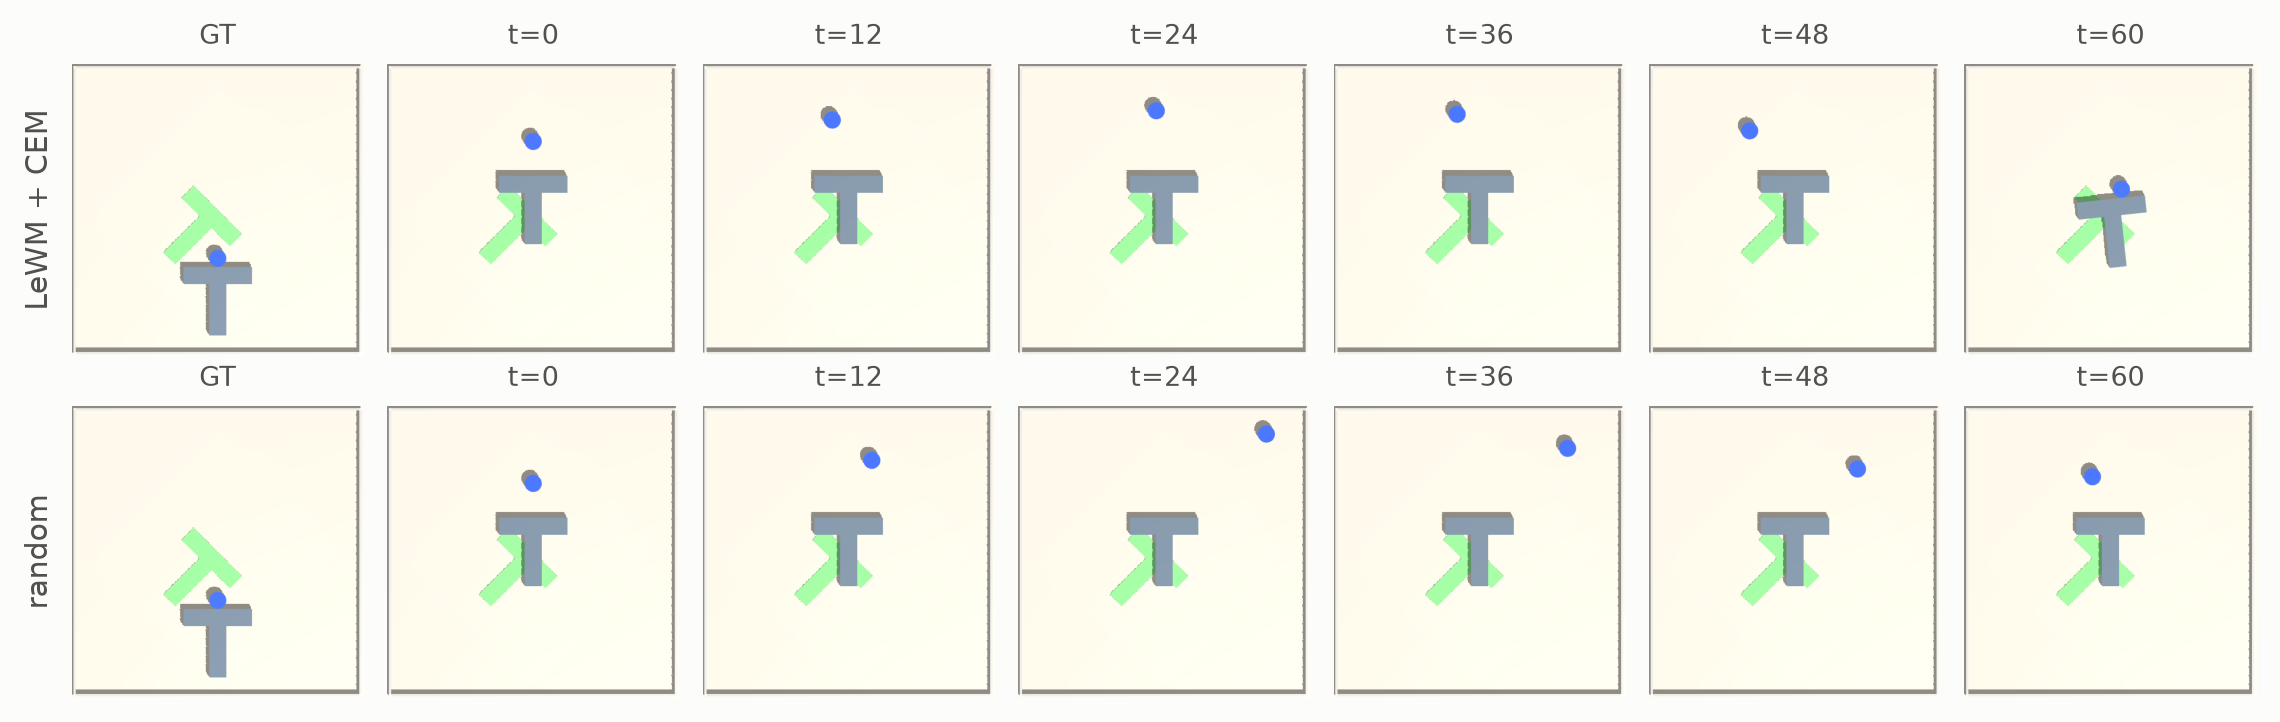

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

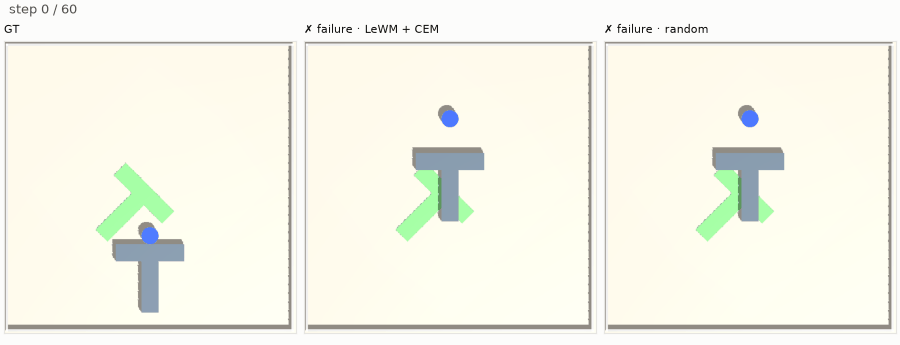

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/benchmarks/20261017_named_worlds/PushT-v0/LeWM/20261017T014731183985Z-c05b887d


In [6]:
show_results(result)
print("Saved run:", result["run_dir"])


In [7]:
world.close()
